=== Lima Data Pertama ===


,komentar,sentimen
0,Program kopdes membuat kami bersyukur.,bahagia
1,"Koperasi desa ini terasa sangat membantu, kami...",bahagia
2,Kopdes Merah Putih harusnya jadi cahaya di des...,sedih
3,Kopdes di desa kami belum juga memberi harapan...,sedih
4,"Pengurus kopdes membuat warga kesal dan marah,...",marah



Jumlah data: 200

Jumlah setiap sentimen:
sentimen
bahagia    67
sedih      67
marah      66
Name: count, dtype: int64

=== Hasil Text Preprocessing ===


,komentar,komentar_bersih,sentimen
0,Program kopdes membuat kami bersyukur.,program kopdes membuat kami bersyukur,bahagia
1,"Koperasi desa ini terasa sangat membantu, kami...",koperasi desa terasa sangat membantu kami sena...,bahagia
2,Kopdes Merah Putih harusnya jadi cahaya di des...,kopdes merah putih harusnya jadi cahaya desa t...,sedih
3,Kopdes di desa kami belum juga memberi harapan...,kopdes desa kami belum juga memberi harapan ny...,sedih
4,"Pengurus kopdes membuat warga kesal dan marah,...",pengurus kopdes membuat warga kesal marah sung...,marah


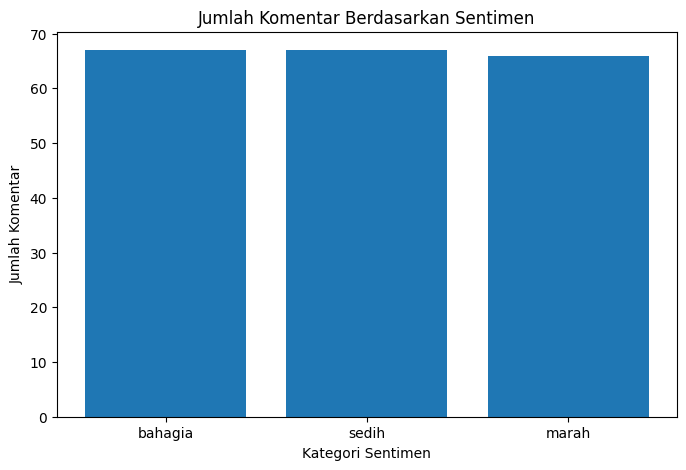

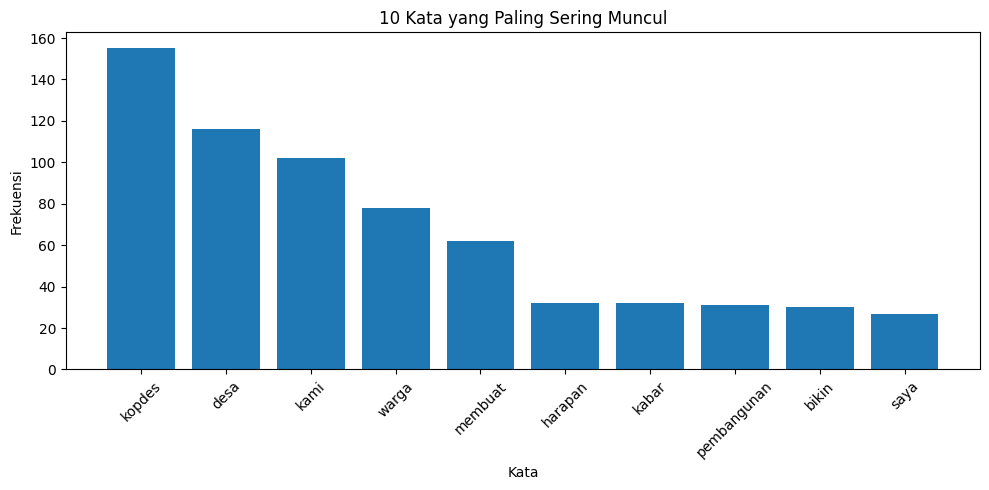


Jumlah data training: 160
Jumlah data testing: 40

Model berhasil dilatih!

Akurasi Model: 95.0 %

Classification Report:
              precision    recall  f1-score   support

     bahagia       1.00      1.00      1.00        14
       marah       0.87      1.00      0.93        13
       sedih       1.00      0.85      0.92        13

    accuracy                           0.95        40
   macro avg       0.96      0.95      0.95        40
weighted avg       0.96      0.95      0.95        40


Chatbot siap digunakan!

 CHATBOT ANALISIS SENTIMEN
 Ketik 'keluar' untuk berhenti

Masukkan komentar: program kopdes membuat saya merasa bersyukur 

Sentimen: BAHAGIA
Chatbot: Terima kasih! Sepertinya Anda puas dengan produk kami.

Silakan masukkan komentar berikutnya.

Masukkan komentar: program kopdes membuat saya geram 

Sentimen: MARAH
Chatbot: Mohon maaf atas ketidaknyamanan yang Anda alami. Kami akan segera mengevaluasi dan memperbaiki layanan kami.

Silakan masukkan komentar berikut

In [4]:

!pip install pandas scikit-learn emoji

import pandas as pd
import matplotlib.pyplot as plt
import re
import string
import emoji

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report


# 1. Membaca Dataset
nama_file = "komentar_kopdes.csv"
data = pd.read_csv(nama_file, encoding="utf-8")

print("=== Lima Data Pertama ===")
display(data.head())

print("\nJumlah data:", len(data))
print("\nJumlah setiap sentimen:")
print(data["sentimen"].value_counts())


# 2. Text Preprocessing
stopwords_indo = [
    "yang", "di", "ke", "dari", "dan", "atau",
    "ini", "itu", "untuk", "dengan", "nya",
    "sih", "aja", "deh", "banget"
]


def preprocessing(teks):
    # Mengubah teks menjadi huruf kecil
    teks = str(teks).lower()

    # Mengganti emoji dengan spasi
    teks = emoji.replace_emoji(teks, replace=" ")

    # Mengganti tanda baca dengan spasi
    teks = teks.translate(
        str.maketrans(
            string.punctuation,
            " " * len(string.punctuation)
        )
    )

    # Menghapus angka
    teks = re.sub(r"\d+", " ", teks)

    # Menghapus stopwords
    kata_bersih = [
        kata for kata in teks.split()
        if kata not in stopwords_indo
    ]

    # Merapikan spasi berlebih
    teks = " ".join(kata_bersih)

    return teks


data["komentar_bersih"] = data["komentar"].apply(preprocessing)

print("\n=== Hasil Text Preprocessing ===")
display(data[["komentar", "komentar_bersih", "sentimen"]].head())


# 3. Grafik Jumlah Sentimen
jumlah_sentimen = data["sentimen"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(jumlah_sentimen.index, jumlah_sentimen.values)

plt.title("Jumlah Komentar Berdasarkan Sentimen")
plt.xlabel("Kategori Sentimen")
plt.ylabel("Jumlah Komentar")
plt.show()


# 4. Menghitung Frekuensi Kata
semua_teks = " ".join(data["komentar_bersih"])
daftar_kata = semua_teks.split()
counter = Counter(daftar_kata)

# Mengambil 10 kata yang paling sering muncul
kata_teratas = counter.most_common(10)

kata = [item[0] for item in kata_teratas]
jumlah = [item[1] for item in kata_teratas]


# 5. Membuat Grafik Frekuensi Kata
plt.figure(figsize=(10, 5))
plt.bar(kata, jumlah)

plt.title("10 Kata yang Paling Sering Muncul")
plt.xlabel("Kata")
plt.ylabel("Frekuensi")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 6. Membagi Data Training dan Testing
X = data["komentar_bersih"]
y = data["sentimen"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\nJumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))


# 7. Vectorization
vectorizer = CountVectorizer()

X_train_vector = vectorizer.fit_transform(X_train)
X_test_vector = vectorizer.transform(X_test)


# 8. Pemodelan Naive Bayes
model = MultinomialNB()
model.fit(X_train_vector, y_train)

print("\nModel berhasil dilatih!")


# 9. Evaluasi Model
y_pred = model.predict(X_test_vector)
akurasi = accuracy_score(y_test, y_pred)

print("\nAkurasi Model:", round(akurasi * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


# 10. Melatih Model Chatbot
vectorizer_chatbot = CountVectorizer()
X_semua = vectorizer_chatbot.fit_transform(X)

model_chatbot = MultinomialNB()
model_chatbot.fit(X_semua, y)

print("\nChatbot siap digunakan!")


# 11. Chatbot Analisis Sentimen
print("\n================================")
print(" CHATBOT ANALISIS SENTIMEN")
print(" Ketik 'keluar' untuk berhenti")
print("================================")

while True:
    komentar = input("\nMasukkan komentar: ")

    # Menghentikan chatbot jika mengetik keluar
    if komentar.strip().lower() == "keluar":
        print("Terima kasih! Chatbot selesai.")
        break

    # Preprocessing komentar
    komentar_bersih = preprocessing(komentar)

    if not komentar_bersih:
        print("Silakan masukkan komentar yang berisi teks.")
        continue

    # Memprediksi sentimen komentar
    komentar_vector = vectorizer_chatbot.transform([komentar_bersih])
    hasil = model_chatbot.predict(komentar_vector)[0]

    # Menentukan respons berdasarkan sentimen
    if hasil == "bahagia":
        respons = "Terima kasih! Sepertinya Anda puas dengan produk kami."

    elif hasil == "sedih":
        respons = "Mohon maaf atas pengalaman Anda. Masukan Anda akan menjadi evaluasi kami."

    elif hasil == "marah":
        respons = "Mohon maaf atas ketidaknyamanan yang Anda alami. Kami akan segera mengevaluasi dan memperbaiki layanan kami."

    else:
        respons = "Terima kasih atas masukannya. Kami akan terus meningkatkan layanan."

    print("\nSentimen:", hasil.upper())
    print("Chatbot:", respons)

    print("\nSilakan masukkan komentar berikutnya.")
